# Notebook 13 – EDA Report

Complete EDA summary of the Telco Customer Churn dataset.

**Sprint 4 – Data Inspection & Exploratory Data Analysis**  
Workflow: `Load → Inspect → Understand → Analyze → Visualize → Identify Problems → Document Findings`  
**Dataset:** Telco Customer Churn (IBM sample data, 7,043 customers × 21 columns)

In [1]:
import os, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid", palette="deep")
pd.set_option("display.max_columns", 50)
pd.set_option("display.width", 140)

# Load the RAW dataset (nothing has been modified yet)
PATH = "../data/telco.csv"
if not os.path.exists(PATH):   # fallback: download straight from the public source
    PATH = "https://raw.githubusercontent.com/IBM/telco-customer-churn-on-icp4d/master/data/Telco-Customer-Churn.csv"
df_raw = pd.read_csv(PATH)
df = df_raw.copy()
print("Loaded:", df.shape)

# NOTE: 'TotalCharges' is stored as text in the raw file (11 blank strings, see 03_Data_Quality).
# For ANALYSIS ONLY we create a numeric working copy; blanks become NaN. The raw file is untouched,
# and the formal treatment of these rows is deferred to the preprocessing sprint.
df["TotalCharges"] = pd.to_numeric(df["TotalCharges"], errors="coerce")

num_cols = ["tenure", "MonthlyCharges", "TotalCharges"]
cat_cols = [c for c in df.columns if c not in num_cols + ["customerID"]]
target = "Churn"
df["ChurnFlag"] = (df["Churn"] == "Yes").astype(int)   # helper for rates/correlations (analysis only)

Loaded: (7043, 21)


### Topic Explanation

This topic focuses on dataset overview. Read the existing notes, follow the example cells, and explain what the resulting output tells you.

## 1. Dataset Overview

In [2]:
overview = pd.DataFrame({
    "Item": ["Dataset", "Source", "Domain", "Size (rows × columns)", "Grain", "Features", "Identifier", "Target", "Date/time columns"],
    "Value": ["Telco Customer Churn", "IBM sample dataset (Watson Analytics / Cloud Pak for Data)", "Telecommunications (subscription services)",
              f"{df_raw.shape[0]:,} × {df_raw.shape[1]}", "One row per customer", "19 (3 numerical, 16 categorical)", "customerID",
              "Churn (Yes/No) – binary classification", "None"],
})
overview

,Item,Value
0,Dataset,Telco Customer Churn
1,Source,IBM sample dataset (Watson Analytics / Cloud P...
2,Domain,Telecommunications (subscription services)
3,Size (rows × columns),"7,043 × 21"
4,Grain,One row per customer
5,Features,"19 (3 numerical, 16 categorical)"
6,Identifier,customerID
7,Target,Churn (Yes/No) – binary classification
8,Date/time columns,None


**Summary:** a 7,043-customer telecom snapshot with demographic, service, contract and billing attributes. The business question is *which customers churn and why?*

### Topic Explanation

This topic focuses on data quality. Read the existing notes, follow the example cells, and explain what the resulting output tells you.

## 2. Data Quality

In [3]:
blank = int((df_raw["TotalCharges"].astype(str).str.strip() == "").sum())
quality = pd.DataFrame([
    ["Missing values (isnull)", int(df_raw.isnull().sum().sum()), "No true NaN"],
    ["Hidden missing values (blank strings in TotalCharges)", blank, "All have tenure = 0 (structural)"],
    ["Completely duplicated rows", int(df_raw.duplicated().sum()), "None"],
    ["Duplicate customerID", int(df_raw.customerID.duplicated().sum()), "None"],
    ["Rows identical except ID", int(df_raw.drop(columns="customerID").duplicated().sum()), "Valid customers with same plan; keep"],
    ["Negative / impossible numeric values", int((df.tenure < 0).sum() + (df.MonthlyCharges <= 0).sum() + (df.TotalCharges < 0).sum()), "None"],
    ["Data-type issues", 2, "TotalCharges (text→float), SeniorCitizen (int→categorical)"],
    ["Redundant category levels", 2, "'No internet service' (6 columns) and 'No phone service' (1 column)"],
], columns=["Check", "Count", "Comment"])
quality

,Check,Count,Comment
0,Missing values (isnull),0,No true NaN
1,Hidden missing values (blank strings in TotalC...,11,All have tenure = 0 (structural)
2,Completely duplicated rows,0,None
3,Duplicate customerID,0,None
4,Rows identical except ID,22,Valid customers with same plan; keep
5,Negative / impossible numeric values,0,None
6,Data-type issues,2,"TotalCharges (text→float), SeniorCitizen (int→..."
7,Redundant category levels,2,'No internet service' (6 columns) and 'No phon...


**Summary:** overall quality is high. Problems are representational (dtype, hidden blanks, redundant levels), not structural.

### Topic Explanation

This topic focuses on statistical findings. Read the existing notes, follow the example cells, and explain what the resulting output tells you.

## 3. Statistical Findings

In [4]:
desc = df[num_cols].agg(["count", "mean", "median", "std", "min", "max", "skew", "kurt"]).T
desc["IQR"] = df[num_cols].quantile(.75) - df[num_cols].quantile(.25)
desc.round(2)

,count,mean,median,std,min,max,skew,kurt,IQR
tenure,7043.0,32.37,29.00,24.56,0.00,72.00,0.24,-1.39,46.00
MonthlyCharges,7043.0,64.76,70.35,30.09,18.25,118.75,-0.22,-1.26,54.35
TotalCharges,7032.0,2283.30,1397.48,2266.77,18.80,8684.80,0.96,-0.23,3393.29


       feature  IQR_outliers
        tenure             0
MonthlyCharges             0
  TotalCharges             0


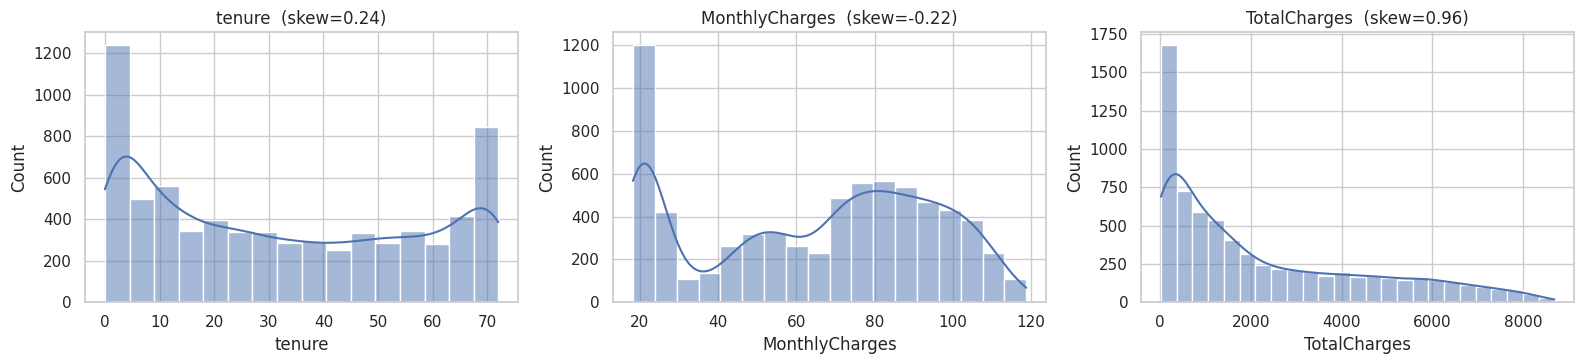

In [5]:
# outlier summary (IQR rule)
rows = []
for c in num_cols:
    s = df[c].dropna(); q1, q3 = s.quantile([.25, .75]); i = q3 - q1
    rows.append((c, int(((s < q1 - 1.5*i) | (s > q3 + 1.5*i)).sum())))
print(pd.DataFrame(rows, columns=["feature", "IQR_outliers"]).to_string(index=False))

fig, axes = plt.subplots(1, 3, figsize=(16, 3.8))
for ax, c in zip(axes, num_cols):
    sns.histplot(df[c].dropna(), kde=True, ax=ax); ax.set_title(f"{c}  (skew={df[c].skew():.2f})")
plt.tight_layout(); plt.show()

* **Central tendency:** mean tenure ≈ 32 months, median 29; mean monthly bill ≈ \$65 (median \$70); mean total ≈ \$2,283 (median \$1,397).
* **Dispersion:** wide – std 24.6 months (tenure), \$30 (monthly), \$2,267 (total).
* **Distribution:** tenure U-shaped (peaks at 1 and 72); MonthlyCharges bimodal (≈ \$20 and ≈ \$80); TotalCharges right-skewed (0.96). None is normal.
* **Outliers:** none by IQR or Z-score (|z| > 3) on the raw numerics, and none at the 99.9% Mahalanobis level; about 61 valid, unusual customers (long tenure, cheap phone-only plan) appear at the 99% level. No removal recommended.

### Topic Explanation

This topic focuses on relationship findings. Read the existing notes, follow the example cells, and explain what the resulting output tells you.

## 4. Relationship Findings

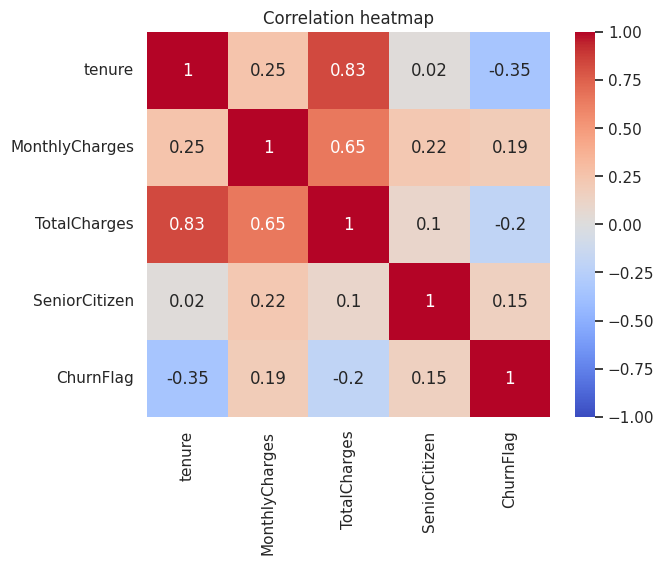

Association with Churn (Cramér's V), top 8:
Contract            0.410
OnlineSecurity      0.347
TechSupport         0.343
InternetService     0.322
PaymentMethod       0.303
OnlineBackup        0.292
DeviceProtection    0.282
StreamingMovies     0.231

Weakest:
MultipleLines    0.040
PhoneService     0.011
gender           0.008


In [6]:
corr = df[["tenure", "MonthlyCharges", "TotalCharges", "SeniorCitizen", "ChurnFlag"]].corr().round(2)
plt.figure(figsize=(6.5, 5)); sns.heatmap(corr, annot=True, cmap="coolwarm", center=0, vmin=-1, vmax=1); plt.title("Correlation heatmap"); plt.show()

def cramers_v(x, y):
    ct = pd.crosstab(x, y); chi2, p, *_ = stats.chi2_contingency(ct)
    return np.sqrt(chi2 / (ct.values.sum() * (min(ct.shape) - 1)))
cats = [c for c in cat_cols if c != "Churn"]
top = pd.Series({c: cramers_v(df[c], df["Churn"]) for c in cats}).sort_values(ascending=False).round(3)
print("Association with Churn (Cramér's V), top 8:"); print(top.head(8).to_string())
print("\nWeakest:"); print(top.tail(3).to_string())

* **Correlations:** tenure–TotalCharges 0.83 (strong), MonthlyCharges–TotalCharges 0.65, tenure–MonthlyCharges 0.25 (weak); tenure–Churn –0.35 (negative).
* **Multicollinearity:** `TotalCharges` ≈ tenure × MonthlyCharges → redundant for linear models.
* **Categorical associations:** Contract strongest; then OnlineSecurity, TechSupport, InternetService, PaymentMethod. gender and PhoneService show no useful relation.
* **Patterns:** short tenure, month-to-month, fibre, electronic check, no security/support, senior, single → higher churn. Combined segment ≈ 60% churn.

### Topic Explanation

This topic focuses on visualization findings. Read the existing notes, follow the example cells, and explain what the resulting output tells you.

## 5. Visualization Findings

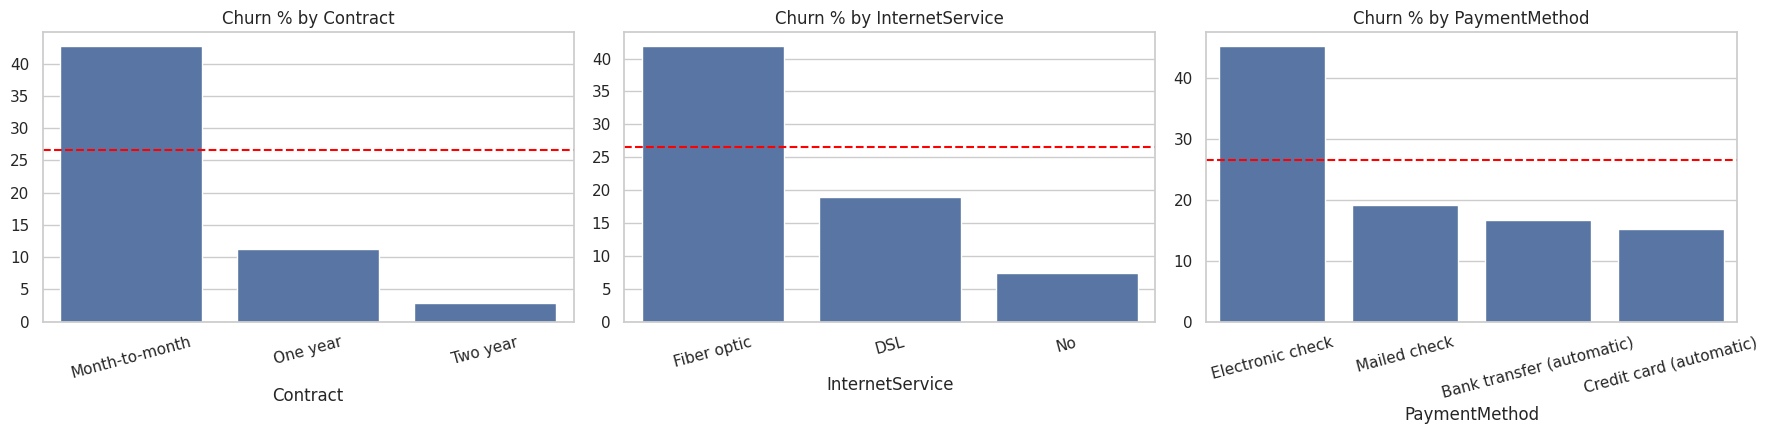

In [7]:
fig, axes = plt.subplots(1, 3, figsize=(18, 4.5))
for ax, c in zip(axes, ["Contract", "InternetService", "PaymentMethod"]):
    r = df.groupby(c)["ChurnFlag"].mean().mul(100).sort_values(ascending=False)
    sns.barplot(x=r.index, y=r.values, ax=ax); ax.axhline(df.ChurnFlag.mean()*100, color="red", ls="--")
    ax.set_title(f"Churn % by {c}"); ax.tick_params(axis="x", rotation=15)
plt.tight_layout(); plt.show()

Most important visual insights: (1) churn falls steeply with tenure and with contract length; (2) churners pay more per month; (3) fibre and electronic-check customers churn most; (4) MonthlyCharges is bimodal because of the no-internet group; (5) tenure shows capped (72) and recent-sign-up spikes.

### Topic Explanation

This topic studies the outcome variable's type, distribution, class balance, and differences across important segments.

## 6. Target Summary

In [8]:
t = df["Churn"].value_counts(); print(pd.DataFrame({"count": t, "percent": (t / t.sum() * 100).round(2)}))
print(f"Imbalance ratio ≈ {t.max() / t.min():.2f}:1 | majority-class baseline accuracy = {t.max() / t.sum():.1%}")

       count  percent
Churn                
No      5174    73.46
Yes     1869    26.54
Imbalance ratio ≈ 2.77:1 | majority-class baseline accuracy = 73.5%


### Topic Explanation

This topic focuses on potential data problems (to address in the next sprint). Read the existing notes, follow the example cells, and explain what the resulting output tells you.

## 7. Potential Data Problems (to address in the next sprint)

| # | Problem | Evidence | Severity |
|---|---|---|---|
| 1 | `TotalCharges` stored as text | dtype = object/str; 11 blank strings | High |
| 2 | 11 structurally missing `TotalCharges` | all have tenure = 0 | High |
| 3 | `SeniorCitizen` encoded as integer | 0/1 flag | Low |
| 4 | Redundant levels 'No internet service' / 'No phone service' | 6 + 1 columns | Medium |
| 5 | Identifier `customerID` | 7,043 unique values | Medium (drop) |
| 6 | Target imbalance | 73.5% / 26.5% | Medium |
| 7 | Multicollinearity: `TotalCharges` vs tenure × MonthlyCharges | r = 0.83, high VIF | Medium |
| 8 | Skewed / bimodal numerics | skew 0.96; bimodal bill | Medium |
| 9 | Different numeric scales | tenure 0–72, charges up to ~8,700 | Medium |
| 10 | Right-censored tenure (cap at 72) | 362 customers at 72 | Low–Medium |
| 11 | Near-duplicate rows (ignoring ID) | 22 extra rows | Low |
| 12 | Weak features | gender, PhoneService | Low |

## 8. Recommendations (what should potentially be done next – *not performed in this sprint*)

* **Data-type correction:** convert `TotalCharges` to float; treat `SeniorCitizen` as categorical.
* **Missing-value treatment:** fill the 11 blanks with 0 (tenure = 0), optionally add a flag.
* **Category cleaning:** merge 'No internet service' / 'No phone service' with 'No'.
* **Encoding:** binary → 0/1; `Contract` → ordinal; `PaymentMethod`, `InternetService` → one-hot; drop `customerID`.
* **Scaling:** standardise numerics for linear/distance-based models.
* **Feature transformation:** consider sqrt on `TotalCharges`; tenure bins.
* **Feature engineering:** `avg_monthly_spend`, number of add-on services, `HasInternet`, risk-segment flags, price-change indicator.
* **Outlier treatment:** none required; keep all rows (document reasoning).
* **Feature selection:** drop/deprioritise `gender`, `PhoneService`; consider dropping `TotalCharges` for linear models.
* **Target handling:** stratified train/test split; evaluate with recall/precision/F1/PR-AUC; try class weights.

## 9. Conclusion
The dataset is clean enough for modelling after light, well-understood corrections. The data clearly show that churn is driven mainly by **short tenure, month-to-month contracts, fibre service, electronic-check billing and absence of security/support services**. The next sprint should implement the corrections above before any model is trained.